In [1]:
import numpy as np
import matplotlib.pyplot as plt

Create the synthetic image


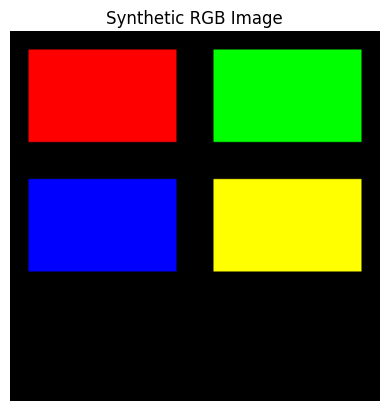

Image shape: (200, 200, 3)
Data type: uint8


In [2]:
# Create a blank black image
img = np.zeros((200, 200, 3), dtype=np.uint8)

# Fill four regions with different colours
img[10:60, 10:90] = np.full((50, 80, 3), [255, 0, 0], dtype=np.uint8)
img[10:60, 110:190] = np.full((50, 80, 3), [0, 255, 0], dtype=np.uint8)
img[80:130, 10:90] = np.full((50, 80, 3), [0, 0, 255], dtype=np.uint8)
img[80:130, 110:190] = np.full((50, 80, 3), [255, 255, 0], dtype=np.uint8)

plt.imshow(img)
plt.title("Synthetic RGB Image")
plt.axis("off")
plt.show()

print("Image shape:", img.shape)
print("Data type:", img.dtype)


Draw stripes using 3D slicing

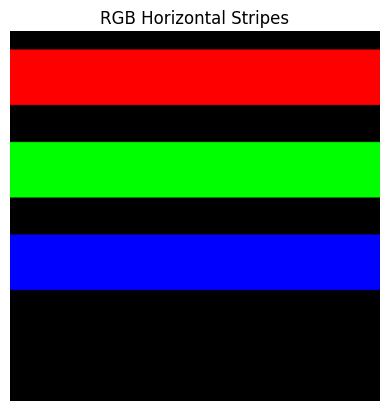

In [3]:

# Create a blank black image
stripes = np.zeros((200, 200, 3), dtype=np.uint8)

# Red horizontal stripe
stripes[10:40, :, 0] = 255

# Green horizontal stripe
stripes[60:90, :, 1] = 255

# Blue horizontal stripe
stripes[110:140, :, 2] = 255

# Display the image
plt.imshow(stripes)
plt.title("RGB Horizontal Stripes")
plt.axis("off")
plt.show()


Crop, Flip, and Extract RGB Channels in Google Colab


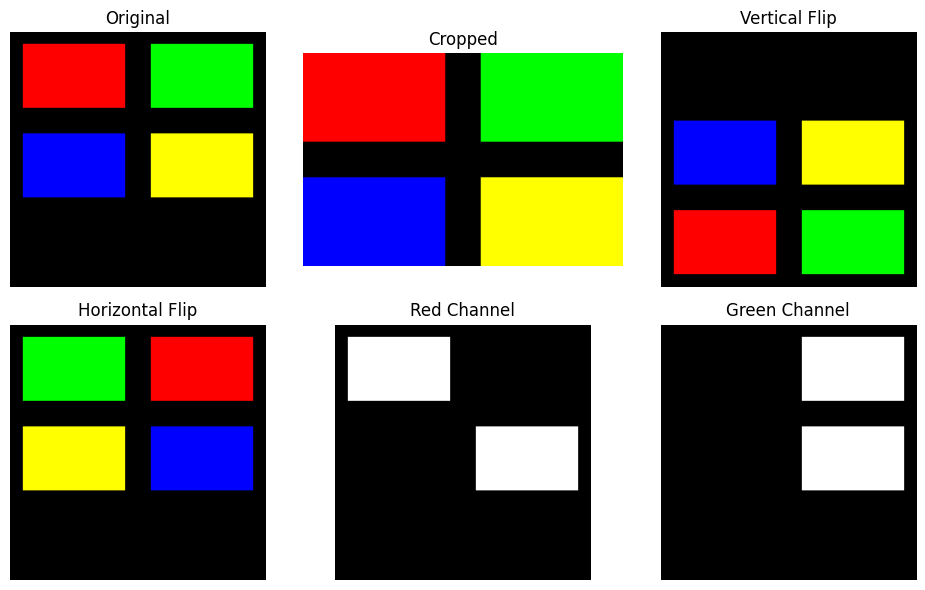

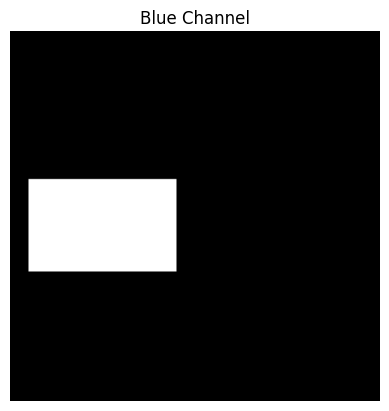

In [4]:

# 1. Crop the image
cropped = img[10:130, 10:190, :]

# 2. Flip the image vertically
vertical_flip = img[::-1, :, :]

# 3. Flip the image horizontally
horizontal_flip = img[:, ::-1, :]

# 4. Extract RGB channels
red_channel = img[:, :, 0]
green_channel = img[:, :, 1]
blue_channel = img[:, :, 2]

# Display the results
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

axes[0, 0].imshow(img)
axes[0, 0].set_title("Original")

axes[0, 1].imshow(cropped)
axes[0, 1].set_title("Cropped")

axes[0, 2].imshow(vertical_flip)
axes[0, 2].set_title("Vertical Flip")

axes[1, 0].imshow(horizontal_flip)
axes[1, 0].set_title("Horizontal Flip")

axes[1, 1].imshow(red_channel, cmap="gray")
axes[1, 1].set_title("Red Channel")

axes[1, 2].imshow(green_channel, cmap="gray")
axes[1, 2].set_title("Green Channel")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display the blue channel separately
plt.imshow(blue_channel, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")
plt.show()


Brightness adjustment and Boolean masking


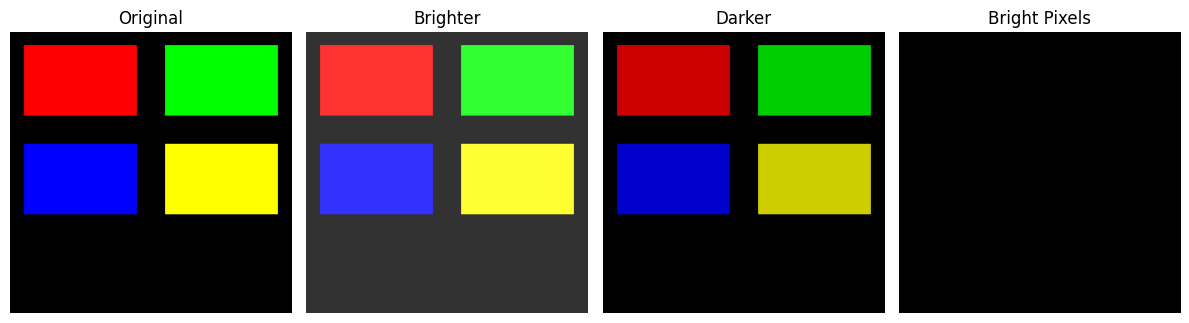

Number of bright pixels: 0


In [5]:

# Convert to float32 before doing arithmetic
img_float = img.astype(np.float32)

# Increase brightness
brighter = np.clip(img_float + 50, 0, 255).astype(np.uint8)

# Decrease brightness
darker = np.clip(img_float - 50, 0, 255).astype(np.uint8)

# Find pixels whose average RGB brightness is above 180
brightness = img_float.mean(axis=2)
bright_mask = brightness > 180

# Create an image showing only bright pixels
bright_pixels = np.zeros_like(img)
bright_pixels[bright_mask] = img[bright_mask]

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

axes[0].imshow(img)
axes[0].set_title("Original")

axes[1].imshow(brighter)
axes[1].set_title("Brighter")

axes[2].imshow(darker)
axes[2].set_title("Darker")

axes[3].imshow(bright_pixels)
axes[3].set_title("Bright Pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Number of bright pixels:", np.count_nonzero(bright_mask))


Compare memory usage


In [6]:

# Compare the same image stored in different data types
image_uint8 = img.astype(np.uint8)
image_float64 = img.astype(np.float64)

print("Image shape:", img.shape)
print("uint8 memory:", image_uint8.nbytes, "bytes")
print("float64 memory:", image_float64.nbytes, "bytes")

print("uint8 data type:", image_uint8.dtype)
print("float64 data type:", image_float64.dtype)

print("Memory ratio:",
      image_float64.nbytes // image_uint8.nbytes)


Image shape: (200, 200, 3)
uint8 memory: 120000 bytes
float64 memory: 960000 bytes
uint8 data type: uint8
float64 data type: float64
Memory ratio: 8


In [7]:

from google.colab import files

uploaded = files.upload()


Saving archive (3).zip to archive (3).zip


In [8]:

import zipfile
import os

zip_file = next(iter(uploaded.keys()))

extract_path = "/content/kaggle_images"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path)[:10])


Dataset extracted successfully!
['landscape_dataset', 'ReadMe.txt']


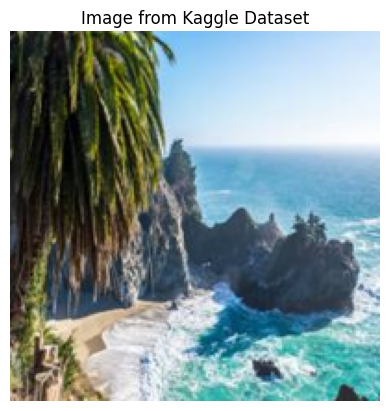

Shape: (200, 200, 3)
Data type: uint8


In [9]:

import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

image_path = None

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(root, filename)
            break
    if image_path:
        break

if image_path:
    image = Image.open(image_path).convert("RGB")
    image = image.resize((200, 200))

    real_img = np.array(image, dtype=np.uint8)

    plt.imshow(real_img)
    plt.title("Image from Kaggle Dataset")
    plt.axis("off")
    plt.show()

    print("Shape:", real_img.shape)
    print("Data type:", real_img.dtype)
else:
    print("No JPG or PNG image found.")


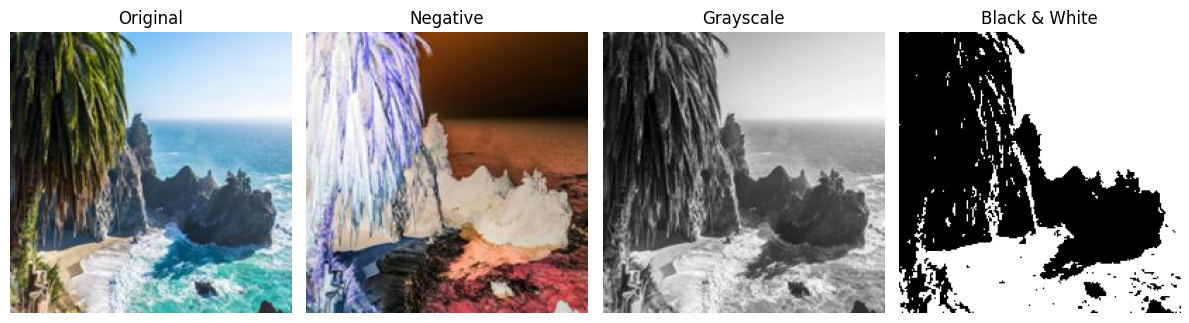

In [10]:

# Use your Kaggle image if available
source = real_img if "real_img" in globals() else img

# 1. Negative filter
negative = 255 - source

# 2. Grayscale filter using weighted RGB values
gray = (
    0.299 * source[:, :, 0].astype(np.float32)
    + 0.587 * source[:, :, 1].astype(np.float32)
    + 0.114 * source[:, :, 2].astype(np.float32)
).astype(np.uint8)

# 3. Black-and-white threshold filter
threshold = 128
black_white = np.where(gray > threshold, 255, 0).astype(np.uint8)

# Display all four versions
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

axes[0].imshow(source)
axes[0].set_title("Original")

axes[1].imshow(negative)
axes[1].set_title("Negative")

axes[2].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Grayscale")

axes[3].imshow(black_white, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Black & White")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Create a simple image-processing dashboard

In [11]:

from IPython.display import display
import ipywidgets as widgets

source = real_img if "real_img" in globals() else img

brightness_slider = widgets.IntSlider(
    value=0, min=-100, max=100, step=10,
    description="Brightness"
)

threshold_slider = widgets.IntSlider(
    value=128, min=0, max=255, step=5,
    description="Threshold"
)

def update_image(brightness, threshold):
    adjusted = np.clip(
        source.astype(np.float32) + brightness, 0, 255
    ).astype(np.uint8)

    gray = (
        0.299 * adjusted[:, :, 0].astype(np.float32)
        + 0.587 * adjusted[:, :, 1].astype(np.float32)
        + 0.114 * adjusted[:, :, 2].astype(np.float32)
    )

    mask = gray > threshold

    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    axes[0].imshow(source)
    axes[0].set_title("Original")

    axes[1].imshow(adjusted)
    axes[1].set_title("Brightness Adjusted")

    axes[2].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Threshold Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

dashboard = widgets.interactive_output(
    update_image,
    {
        "brightness": brightness_slider,
        "threshold": threshold_slider
    }
)

display(brightness_slider, threshold_slider, dashboard)


IntSlider(value=0, description='Brightness', min=-100, step=10)

IntSlider(value=128, description='Threshold', max=255, step=5)

Output()

another image

In [12]:

from google.colab import files

uploaded_image = files.upload()


Saving butterfly.avif to butterfly.avif


Convert your photo into a NumPy array

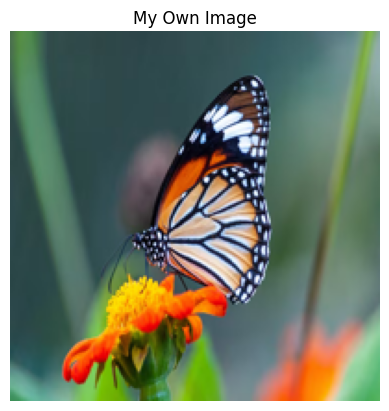

Image shape: (200, 200, 3)
Data type: uint8


In [13]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Get the uploaded image filename
image_path = next(iter(uploaded_image.keys()))

# Open the image and convert it to RGB
photo = Image.open(image_path).convert("RGB")

# Resize it for easier processing
photo = photo.resize((200, 200))

# Convert the photo into a NumPy array
real_img = np.array(photo, dtype=np.uint8)

# Display the image
plt.imshow(real_img)
plt.title("My Own Image")
plt.axis("off")
plt.show()

print("Image shape:", real_img.shape)
print("Data type:", real_img.dtype)


image-processing operations

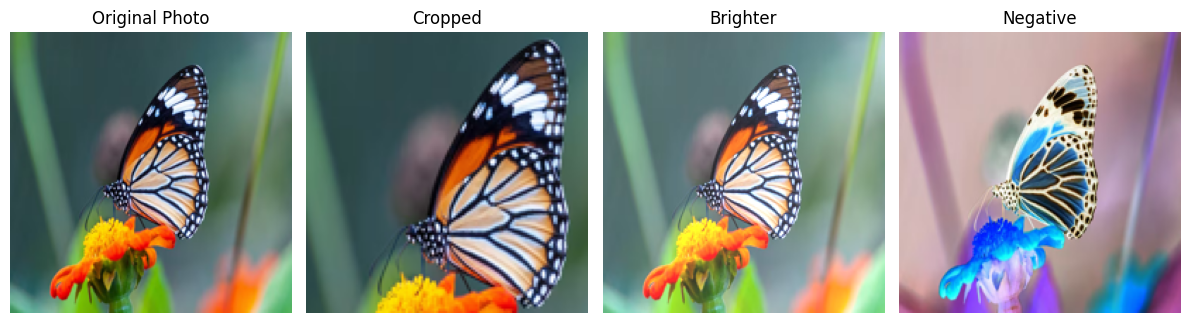

In [14]:

# Crop the photo
cropped = real_img[20:150, 20:150, :]

# Increase brightness
brighter = np.clip(
    real_img.astype(np.float32) + 40, 0, 255
).astype(np.uint8)

# Apply a negative filter
negative = 255 - real_img

# Display all results
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

axes[0].imshow(real_img)
axes[0].set_title("Original Photo")

axes[1].imshow(cropped)
axes[1].set_title("Cropped")

axes[2].imshow(brighter)
axes[2].set_title("Brighter")

axes[3].imshow(negative)
axes[3].set_title("Negative")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
